# Rainfall Predictability Analysis over Odisha
Can past rainfall predict Odisha's monthly rainfall better than a simple seasonal average?

In [13]:
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

BASE = Path.cwd().parent if Path.cwd().name.lower() == "notebook" else Path.cwd()
DATA_DIR = BASE / "Data"
FIG_DIR = BASE / "Figures"
OUT_CSV = DATA_DIR / "odisha_monthly_rainfall.csv"
if not FIG_DIR.exists():
    FIG_DIR.mkdir()

NLAT, NLON = 129, 135
lat = 6.5 + 0.25 * np.arange(NLAT)
lon = 66.5 + 0.25 * np.arange(NLON)
box = ((lat >= 17.8) & (lat <= 22.6))[:, None] & ((lon >= 81.3) & (lon <= 87.5))[None, :]

files = sorted(p for p in DATA_DIR.glob("Rainfall_ind*_rfp25.grd") if p.is_file())
print(len(files), "files found in", DATA_DIR)

11 files found in C:\Users\Devashish\Projects\Odisha Rainfall Predictability\Data


## 1. Build the monthly series
Average the daily IMD grids (2016–2025) over the Odisha box, sum them to monthly totals, run quality checks, and save the result as a CSV.

In [7]:
series = []
for path in files:
    year = int(re.search(r"ind(\d{4})", path.name).group(1))
    if not (2016 <= year <= 2025):
        continue
    raw = np.fromfile(path, dtype="<f4")
    days = raw.size // (NLAT * NLON)
    rain = raw.reshape(days, NLAT, NLON)
    rain[rain == -999] = np.nan
    dates = pd.date_range(f"{year}-01-01", periods=days, freq="D")
    series.append(pd.Series(np.nanmean(rain[:, box], axis=1), index=dates))
    print("Loaded", year, days, "days")

daily = pd.concat(series).sort_index()
grp = daily.resample("MS")
monthly = grp.sum().where(grp.count() == grp.size())

print(len(daily), "days;", monthly.notna().sum(), "usable months of", len(monthly))
print("Missing days:", int(daily.isna().sum()), "| Negative values:", int((daily < 0).sum()))

monthly.rename("rainfall_mm").to_csv(OUT_CSV, index_label="date")
print("Saved", OUT_CSV)

Loaded 2016 366 days
Loaded 2017 365 days
Loaded 2018 365 days
Loaded 2019 365 days
Loaded 2020 366 days
Loaded 2021 365 days
Loaded 2022 365 days
Loaded 2023 365 days
Loaded 2024 366 days
Loaded 2025 365 days
3653 days; 120 usable months of 120
Missing days: 0 | Negative values: 0
Saved C:\Users\Devashish\Projects\Odisha Rainfall Predictability\Data\odisha_monthly_rainfall.csv


## 2. Explore the data
Load the monthly CSV and plot the series and the seasonal spread. Rainfall peaks from June to September.

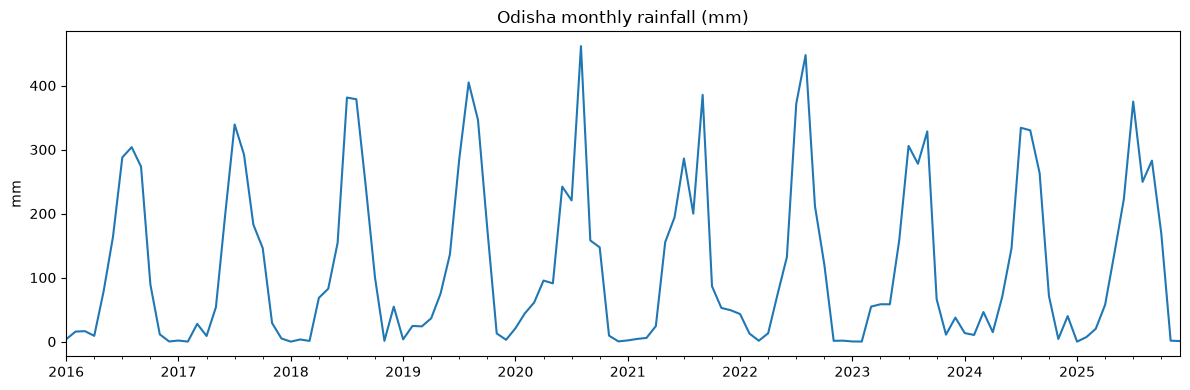

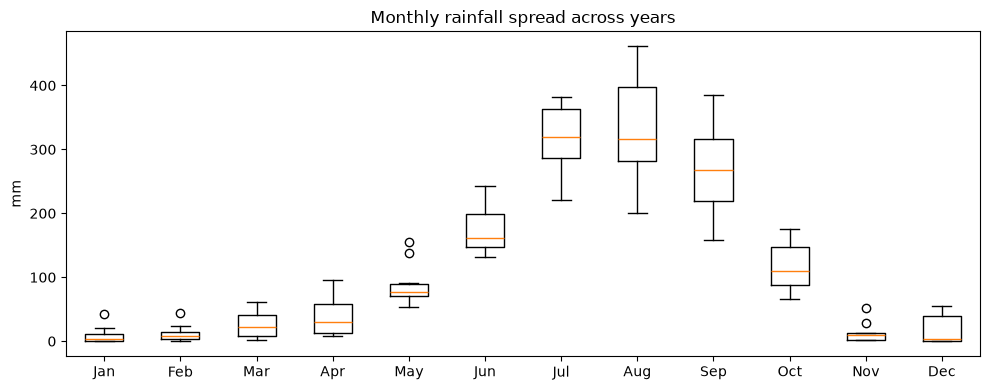

In [8]:
monthly = pd.read_csv(OUT_CSV, index_col="date", parse_dates=True)["rainfall_mm"]

fig, ax = plt.subplots(figsize=(12, 4))
monthly.plot(ax=ax, title="Odisha monthly rainfall (mm)")
ax.set_ylabel("mm"); ax.set_xlabel("")
plt.tight_layout()
fig.savefig(FIG_DIR / "monthly_series.png", dpi=150, bbox_inches="tight")
plt.show()

names = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
by_month = [monthly[monthly.index.month == m].dropna() for m in range(1, 13)]
fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot(by_month)
ax.set_xticks(range(1, 13)); ax.set_xticklabels(names)
ax.set_ylabel("mm"); ax.set_title("Monthly rainfall spread across years")
plt.tight_layout()
fig.savefig(FIG_DIR / "seasonal_spread.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Quick check: 2024–2025 hold-out
Train on 2016–2023, test on the last two years. The baseline is the average rainfall for each calendar month. It is compared with a linear regression on last month's rainfall and last year's rainfall for the same month. This is only 24 test months, so treat it as a first look.

In [9]:
train = monthly[:"2023-12-31"]
test = monthly["2024-01-01":]
clim = train.groupby(train.index.month).mean()
baseline_pred = pd.Series(test.index.month.map(clim).values, index=test.index)

data = pd.DataFrame({"rain": monthly})
data["lag1"] = data["rain"].shift(1)
data["lag12"] = data["rain"].shift(12)
data["month"] = data.index.month
data = data.dropna()
X = pd.get_dummies(data[["lag1", "lag12", "month"]], columns=["month"], drop_first=True).astype(float)
y = data["rain"]

lin = LinearRegression().fit(X[:"2023-12-31"], y[:"2023-12-31"])
pred = pd.Series(np.clip(lin.predict(X["2024-01-01":]), 0, None), index=y["2024-01-01":].index)

print("Baseline MAE:", round(mean_absolute_error(test, baseline_pred), 1), "mm")
print("Linear model MAE:", round(mean_absolute_error(y["2024-01-01":], pred), 1), "mm")

Baseline MAE: 25.9 mm
Linear model MAE: 29.5 mm


## 4. Leave-one-year-out cross-validation (main result)
Hold out each year in turn and compare the baseline with the regression on rainfall anomalies. Compare MAE overall and for each year.

In [10]:
records = []
for Y in sorted(set(monthly.index.year)):
    tr = monthly[monthly.index.year != Y]
    c = tr.groupby(tr.index.month).mean()
    c_all = pd.Series(monthly.index.month.map(c).values, index=monthly.index)
    anom = monthly - c_all
    df = pd.DataFrame({"anom": anom, "l1": anom.shift(1), "l12": anom.shift(12)}).dropna()
    trd, ted = df[df.index.year != Y], df[df.index.year == Y]
    if ted.empty:
        continue
    reg = LinearRegression().fit(trd[["l1", "l12"]], trd["anom"])
    base = c_all.loc[ted.index]
    model = (base + reg.predict(ted[["l1", "l12"]])).clip(lower=0)
    records.append(pd.DataFrame({"year": Y, "actual": monthly.loc[ted.index],
                                 "baseline": base, "model": model}, index=ted.index))

res = pd.concat(records).sort_index()
per_year = pd.DataFrame([
    {"year": yr, "baseline_mae": mean_absolute_error(g.actual, g.baseline),
     "model_mae": mean_absolute_error(g.actual, g.model)}
    for yr, g in res.groupby("year")]).set_index("year").round(1)

print(per_year.to_string())
print("Baseline MAE:", round(mean_absolute_error(res.actual, res.baseline), 1), "mm")
print("Model MAE:", round(mean_absolute_error(res.actual, res.model), 1), "mm")
print("Model better in", int((per_year.model_mae < per_year.baseline_mae).sum()), "of", len(per_year), "years")

      baseline_mae  model_mae
year                         
2017          29.3       32.1
2018          27.2       29.1
2019          30.5       34.9
2020          55.0       58.3
2021          48.3       41.5
2022          36.7       31.3
2023          29.4       23.9
2024          18.3       27.2
2025          34.8       32.1
Baseline MAE: 34.4 mm
Model MAE: 34.5 mm
Model better in 4 of 9 years


## 5. Results plots
Actual vs predicted rainfall, error by test year, and predicted vs actual.

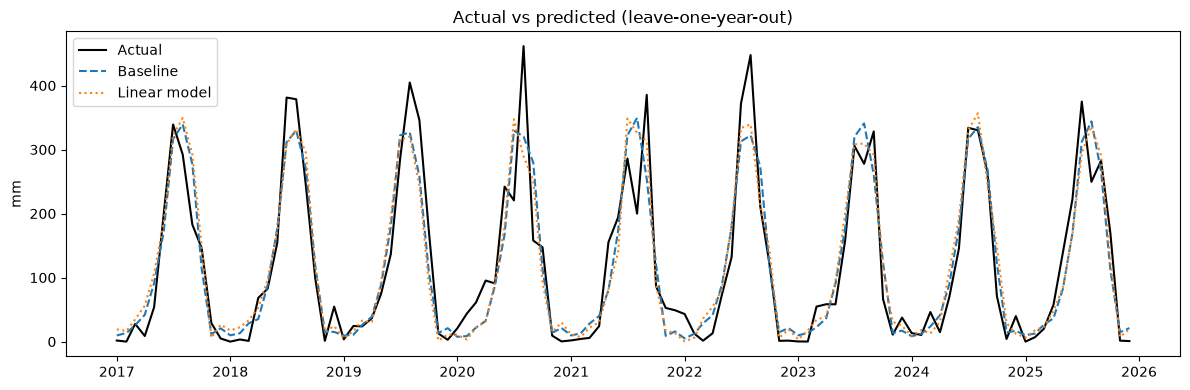

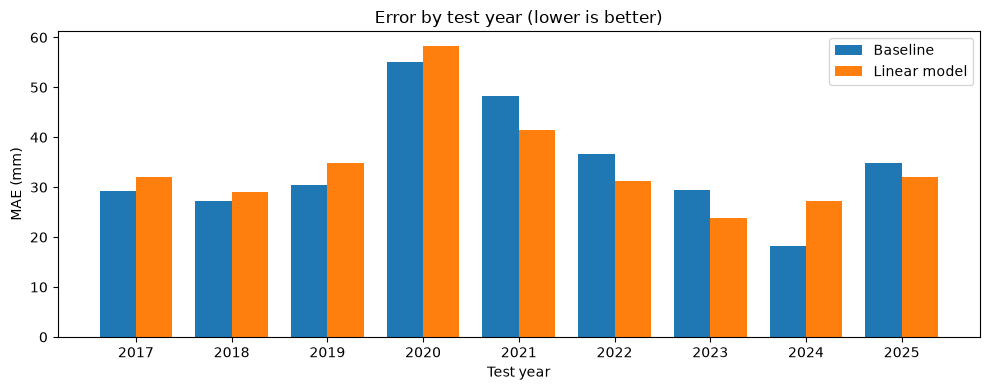

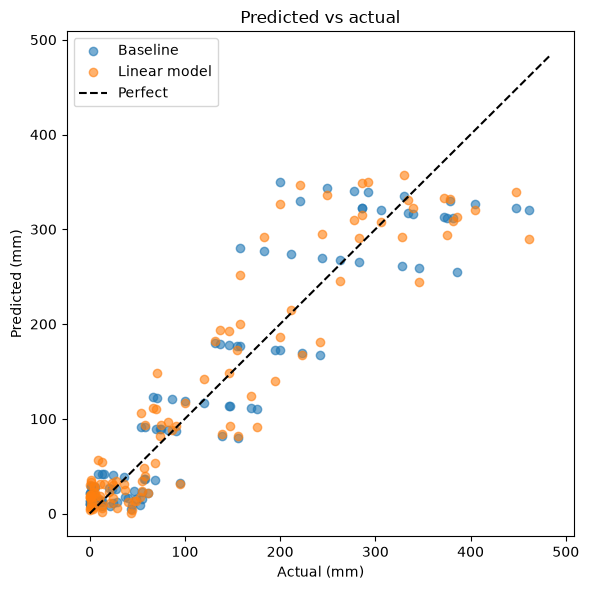

In [11]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(res.index, res.actual, color="black", label="Actual")
ax.plot(res.index, res.baseline, "--", color="tab:blue", label="Baseline")
ax.plot(res.index, res.model, ":", color="tab:orange", label="Linear model")
ax.set_ylabel("mm"); ax.set_title("Actual vs predicted (leave-one-year-out)"); ax.legend()
plt.tight_layout()
fig.savefig(FIG_DIR / "predictions_over_time.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(per_year)); w = 0.38
ax.bar(x - w/2, per_year.baseline_mae, w, label="Baseline", color="tab:blue")
ax.bar(x + w/2, per_year.model_mae, w, label="Linear model", color="tab:orange")
ax.set_xticks(x); ax.set_xticklabels(per_year.index)
ax.set_xlabel("Test year"); ax.set_ylabel("MAE (mm)"); ax.legend()
ax.set_title("Error by test year (lower is better)")
plt.tight_layout()
fig.savefig(FIG_DIR / "mae_per_year.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(res.actual, res.baseline, alpha=0.6, label="Baseline", color="tab:blue")
ax.scatter(res.actual, res.model, alpha=0.6, label="Linear model", color="tab:orange")
top = max(res.actual.max(), res.baseline.max(), res.model.max()) * 1.05
ax.plot([0, top], [0, top], "k--", label="Perfect")
ax.set_xlabel("Actual (mm)"); ax.set_ylabel("Predicted (mm)"); ax.legend()
ax.set_title("Predicted vs actual")
plt.tight_layout()
fig.savefig(FIG_DIR / "predicted_vs_actual.png", dpi=150, bbox_inches="tight")
plt.show()

## Conclusion
The regression did not beat the seasonal baseline (MAE 34.5 vs 34.4 mm, better in only 4 of 9 years). Past rainfall alone adds little forecast skill. Most of the predictable signal is the seasonal cycle.